<a href="https://www.kaggle.com/code/lalit7881/daily-job-listings-eda-98?scriptVersionId=362697441" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")
# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
%matplotlib inline

import seaborn as sns

from pathlib import Path
import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/chandranshbinjola/job-listings/jobs_by_company.csv
/kaggle/input/datasets/chandranshbinjola/job-listings/jobs.csv
/kaggle/input/datasets/chandranshbinjola/job-listings/skill_demand_daily.csv
/kaggle/input/datasets/chandranshbinjola/job-listings/open_jobs_daily.csv


## Loading dataset

In [2]:
DATA_ROOTS = [
    Path('/kaggle/input'),
    Path('/kaggle/input'),
    Path('/kaggle/input/datasets'),
]

def resolve_data_file(file_name=None, suffixes=None):
    suffixes = tuple(suffixes or [])
    for root in DATA_ROOTS:
        if not root.exists():
            continue
        matches = [p for p in root.rglob('*') if p.is_file()]
        if file_name:
            exact = [p for p in matches if p.name == file_name]
            if exact:
                return exact[0]
        if suffixes:
            typed = [p for p in matches if p.suffix.lower() in suffixes]
            if typed:
                return typed[0]
    raise FileNotFoundError(f'Could not resolve data file: {file_name or suffixes}')

In [3]:
jobs_by_company_file = resolve_data_file(file_name='jobs_by_company.csv')
jobs_by_company = pd.read_csv(jobs_by_company_file, encoding='utf-8', delimiter=',')

In [4]:
jobs_file = resolve_data_file(file_name='jobs.csv')
jobs = pd.read_csv(jobs_file, encoding='utf-8', delimiter=',')


In [5]:
skill_demand_file = resolve_data_file(file_name='skill_demand_daily.csv')
skill_demand_daily = pd.read_csv(skill_demand_file, encoding='ascii', delimiter=',')

In [6]:
open_jobs_file = resolve_data_file(file_name='open_jobs_daily.csv')
open_jobs_daily = pd.read_csv(open_jobs_file, encoding='ascii', delimiter=',')

In [7]:
for col in ['posted', 'first_seen', 'closed_at']:
    if col in jobs.columns:
        jobs[col] = pd.to_datetime(jobs[col], errors='coerce')


In [8]:
skill_demand_daily['date'] = pd.to_datetime(skill_demand_daily['date'], errors='coerce')
open_jobs_daily['date'] = pd.to_datetime(open_jobs_daily['date'], errors='coerce')

In [9]:
print('jobs dataset shape:', jobs.shape)

jobs dataset shape: (1040721, 22)


In [10]:
print('jobs_by_company dataset shape:', jobs_by_company.shape)

jobs_by_company dataset shape: (11157, 6)


In [11]:
print('skill_demand_daily dataset shape:', skill_demand_daily.shape)

skill_demand_daily dataset shape: (2509, 5)


In [12]:
print('open_jobs_daily dataset shape:', open_jobs_daily.shape)

open_jobs_daily dataset shape: (23, 3)


## EDA

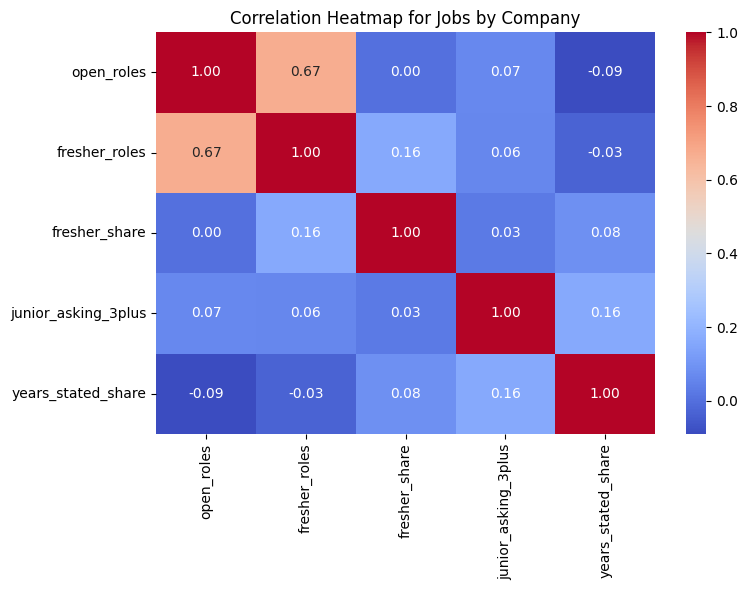

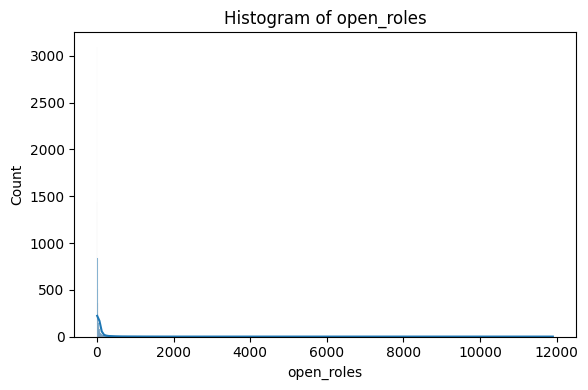

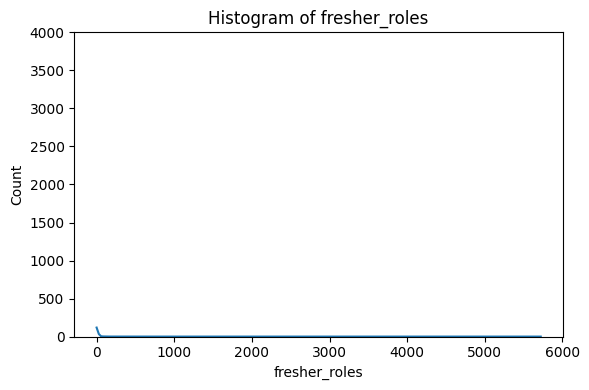

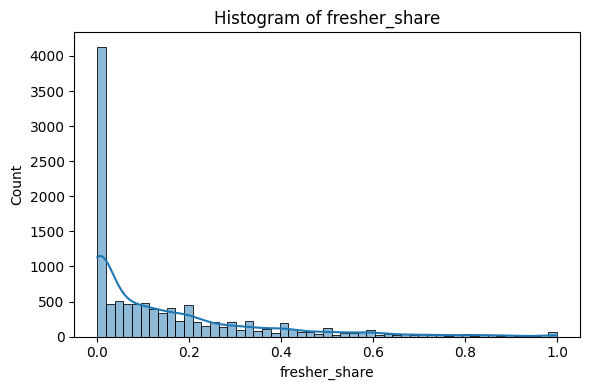

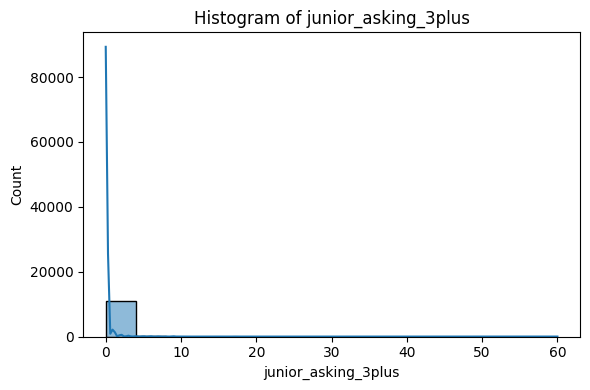

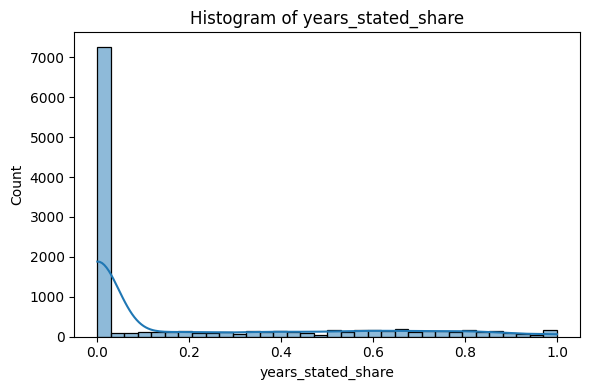

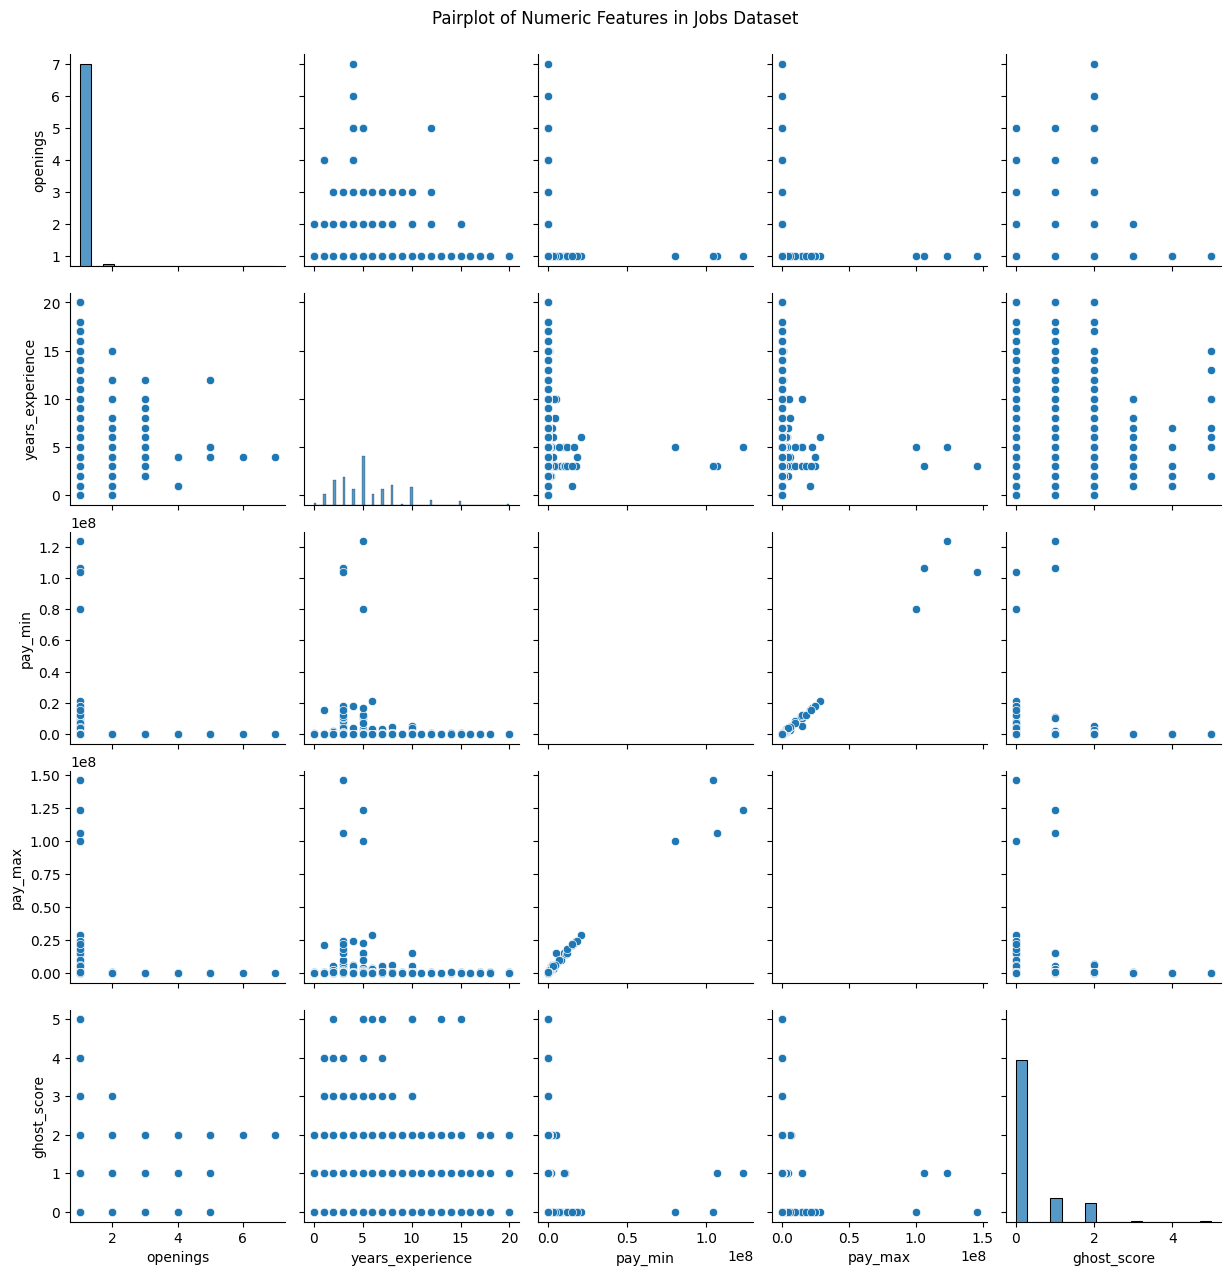

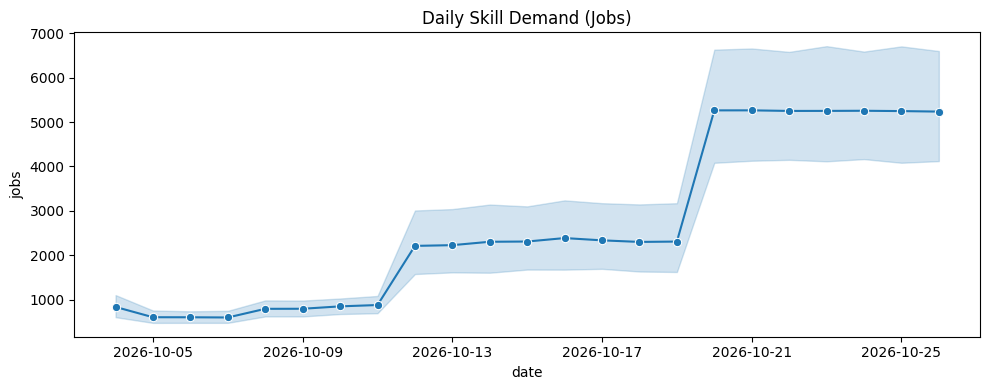

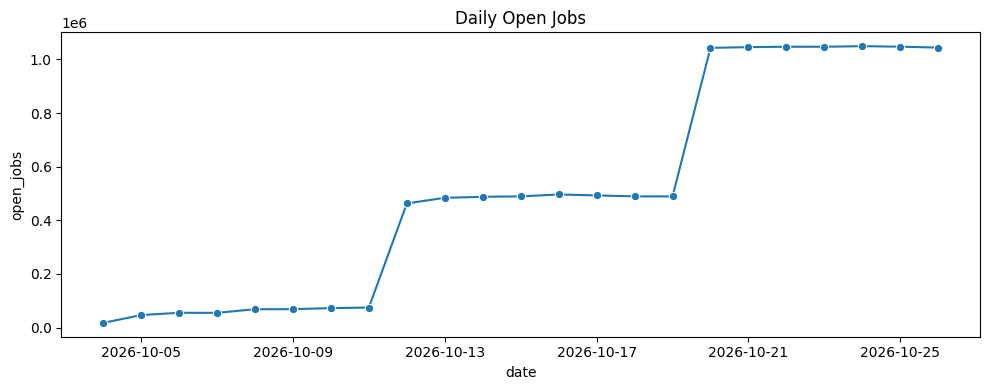

In [13]:

numeric_jbc = jobs_by_company.select_dtypes(include=[np.number])

if numeric_jbc.shape[1] >= 4:
    plt.figure(figsize=(8, 6))
    sns.heatmap(numeric_jbc.corr(), annot=True, cmap='coolwarm', fmt='.2f')
    plt.title('Correlation Heatmap for Jobs by Company')
    plt.tight_layout()
    plt.show()

numeric_jbc.columns
for col in numeric_jbc.columns:
    plt.figure(figsize=(6, 4))
    sns.histplot(numeric_jbc[col], kde=True)
    plt.title(f'Histogram of {col}')
    plt.tight_layout()
    plt.show()

numeric_jobs = jobs.select_dtypes(include=[np.number])

# Use a pair plot if there are at least 2 numeric columns
if numeric_jobs.shape[1] >= 2:
    sns.pairplot(numeric_jobs.dropna())
    plt.suptitle('Pairplot of Numeric Features in Jobs Dataset', y=1.02)
    plt.show()


plt.figure(figsize=(10, 4))
sns.lineplot(data=skill_demand_daily, x='date', y='jobs', marker='o')
plt.title('Daily Skill Demand (Jobs)')
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 4))
sns.lineplot(data=open_jobs_daily, x='date', y='open_jobs', marker='o')
plt.title('Daily Open Jobs')
plt.tight_layout()
plt.show()

## Feature engineering

In [14]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, roc_curve, auc

Prediction Accuracy: 0.9763


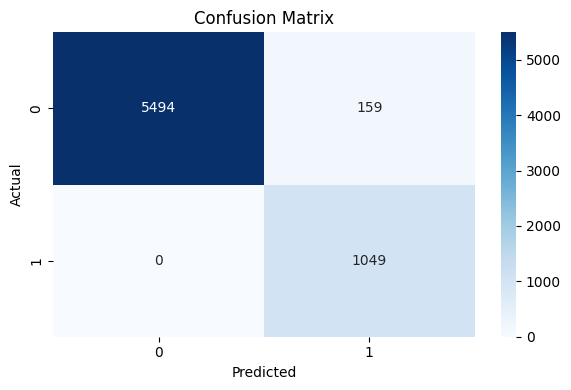

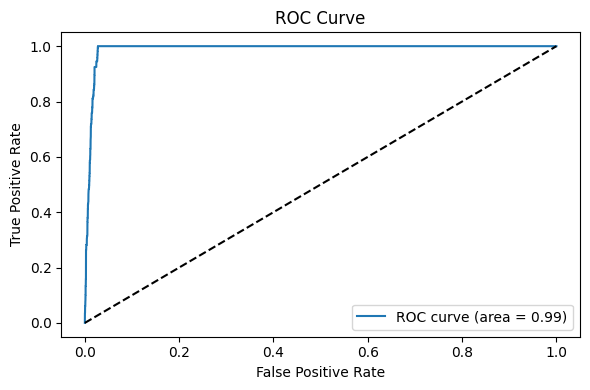

In [15]:
predictor_cols = ['pay_min', 'pay_max', 'years_experience', 'ghost_score']

# We also consider 'openings' if it exists in the jobs dataset
if 'openings' in jobs.columns:
    predictor_cols.append('openings')

# Create a copy of the dataset with the selected features and the target
predict_df = jobs[predictor_cols + ['fresher_friendly']].copy()

# Drop rows with missing values in the selected columns
predict_df.dropna(inplace=True)

# Convert target to integer (0/1), assuming boolean can be mapped
predict_df['fresher_friendly'] = predict_df['fresher_friendly'].astype(int)

# Split data
X = predict_df[predictor_cols]
y = predict_df['fresher_friendly']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Standardize the features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Build and train the logistic regression model
model = LogisticRegression(random_state=42, max_iter=1000)
model.fit(X_train_scaled, y_train)

# Predictions and evaluation
y_pred = model.predict(X_test_scaled)
acc = accuracy_score(y_test, y_pred)
print(f'Prediction Accuracy: {acc:.4f}')

# Confusion Matrix
conf_mat = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(conf_mat, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.tight_layout()
plt.show()

# ROC Curve
y_proba = model.predict_proba(X_test_scaled)[:, 1]
fpr, tpr, thresholds = roc_curve(y_test, y_proba)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(6, 4))
plt.plot(fpr, tpr, label=f'ROC curve (area = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

## Thank you..pls upcvote!!!!!!!!